<a href="https://colab.research.google.com/github/Lakshmi-prasuna/covid-19-detection/blob/main/covid.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

AI-Powered COVID Detection

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os

In [ ]:
# Initialising the CNN
classifier = tf.keras.models.Sequential()

classifier.add(tf.keras.layers.Convolution2D(filters=32, kernel_size=3, padding="same", input_shape=(64, 64, 3),
                                             activation='relu'))

classifier.add(tf.keras.layers.MaxPooling2D(pool_size=2, strides=2, padding='valid'))

classifier.add(tf.keras.layers.Convolution2D(filters=64, kernel_size=3, padding="same", activation="relu"))
classifier.add(tf.keras.layers.MaxPooling2D(pool_size=2, strides=2, padding='valid'))

classifier.add(tf.keras.layers.Flatten())

classifier.add(tf.keras.layers.Dense(units=128, activation='relu'))
classifier.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

classifier.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
classifier.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 64, 64, 32)        896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 32, 32, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 64)        18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 16, 16, 64)        0         
 g2D)                                                            
                                                                 
 flatten (Flatten)           (None, 16384)             0         
                                                                 
 dense (Dense)               (None, 128)               2

In [ ]:
# Part 2 - Fitting the CNN to the images

from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1. / 255,
                                   shear_range=0.2,
                                   zoom_range=0.2,
                                   horizontal_flip=True)

test_datagen = ImageDataGenerator(rescale=1. / 255)

training_set = train_datagen.flow_from_directory('/content/train',
                                                 target_size=(64, 64),
                                                 batch_size=32,
                                                 class_mode='binary')

test_set = test_datagen.flow_from_directory('/content/test',
                                            target_size=(64, 64),
                                            batch_size=32,
                                            class_mode='binary')

Found 100 images belonging to 2 classes.
Found 100 images belonging to 2 classes.


In [ ]:
#training
history = classifier.fit(training_set,
                         steps_per_epoch=4,
                         epochs=10,
                         validation_data=test_set,
                         validation_steps=4)

Epoch 1/10
4/4 [==============================] - 7s 2s/step - loss: 0.6992 - accuracy: 0.4800 - val_loss: 0.5319 - val_accuracy: 0.9400
Epoch 2/10
4/4 [==============================] - 5s 1s/step - loss: 0.5006 - accuracy: 0.8600 - val_loss: 0.3718 - val_accuracy: 0.9600
Epoch 3/10
4/4 [==============================] - 5s 1s/step - loss: 0.3723 - accuracy: 0.8300 - val_loss: 0.2289 - val_accuracy: 0.9500
Epoch 4/10
4/4 [==============================] - 6s 1s/step - loss: 0.2678 - accuracy: 0.8700 - val_loss: 0.2467 - val_accuracy: 0.9400
Epoch 5/10
4/4 [==============================] - 5s 1s/step - loss: 0.2191 - accuracy: 0.9100 - val_loss: 0.5290 - val_accuracy: 0.7900
Epoch 6/10
4/4 [==============================] - 6s 2s/step - loss: 0.7627 - accuracy: 0.7200 - val_loss: 0.1745 - val_accuracy: 0.9500
Epoch 7/10
4/4 [==============================] - 5s 1s/step - loss: 0.4871 - accuracy: 0.8300 - val_loss: 0.2748 - val_accuracy: 0.8900
Epoch 8/10
4/4 [=========================

In [ ]:
classifier.save('my_model.keras')

In [ ]:
# evaluation on test set
loaded_model = tf.keras.models.load_model('my_model.keras')
loaded_model.evaluate(test_set)

4/4 [==============================] - 3s 572ms/step - loss: 0.1560 - accuracy: 0.9700


[0.1560034155845642, 0.9700000286102295]

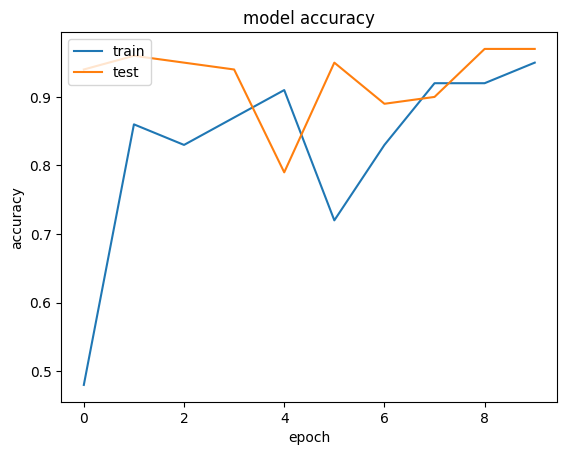

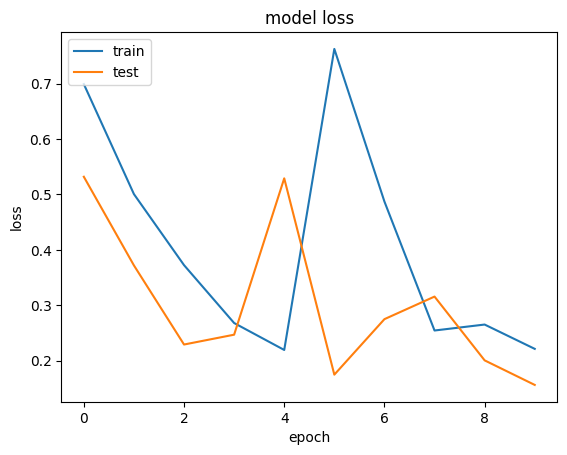

In [ ]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()


1/1 [==============================] - 0s 23ms/step
Normal


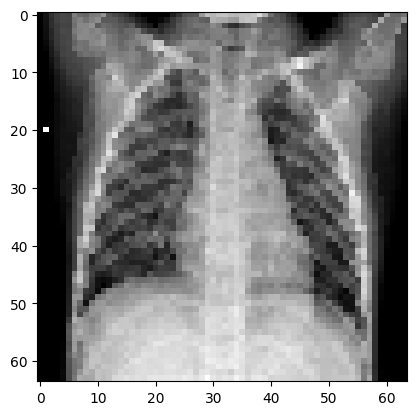

In [ ]:
# for only one prediction
import numpy as np
from tensorflow.keras.preprocessing import image

test_image = image.load_img('/content/test/normal/IM-0266-0001.jpeg',target_size=(64, 64))
plt.imshow(test_image)
test_image = image.img_to_array(test_image)
test_image = np.expand_dims(test_image, axis=0)
result = classifier.predict(test_image)
training_set.class_indices
if result[0][0] == 1:
    prediction = 'Normal'
else:
    prediction = 'Covid'
print(prediction)


In [ ]:
# plot confusion metrix
from tensorflow.keras.models import load_model
classifier = tf.keras.models.load_model('my_model.keras')
y_pred = []
y_test = []
import os

for i in os.listdir("/content/test/normal/"):
    img = image.load_img("/content/test/normal/" + i, target_size=(64, 64))
    img = image.img_to_array(img)
    img = np.expand_dims(img, axis=0)
    p = classifier.predict(img)
    y_test.append(p[0, 0])
    y_pred.append(1)

for i in os.listdir("/content/test/covid/"):
    img = image.load_img("/content/test/covid/" + i, target_size=(64, 64))
    img = image.img_to_array(img)
    img = np.expand_dims(img, axis=0)
    p = classifier.predict(img)
    y_test.append(p[0, 0])
    y_pred.append(0)

y_pred = np.array(y_pred)
y_test = np.array(y_test)

1/1 [==============================] - 0s 22ms/step


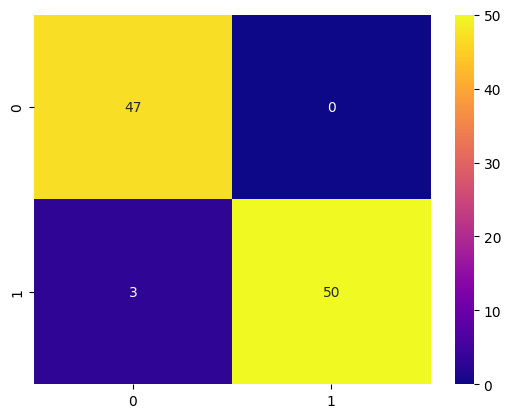

              precision    recall  f1-score   support

           0       0.94      1.00      0.97        47
           1       1.00      0.94      0.97        53

    accuracy                           0.97       100
   macro avg       0.97      0.97      0.97       100
weighted avg       0.97      0.97      0.97       100



In [ ]:
import seaborn as sns
y_pred_binary = np.where(y_pred > 0.5, 1, 0)

# Ensure y_test and y_pred_binary are of the same data type
y_test = y_test.astype(int)  # Convert y_test to integer if needed

# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred_binary)
sns.heatmap(cm, cmap="plasma", annot=True)
plt.show()

# Print classification report
print(classification_report(y_test,y_pred_binary))

['normal', 'covid']
['normal', 'covid']
(32, 64, 64, 3)
{'covid': 0, 'normal': 1}
Training set class distribution:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
Test set class distribution:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


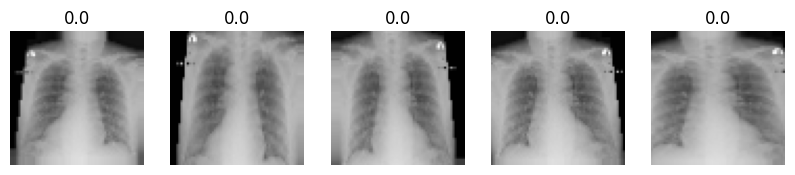

In [ ]:
# Check directory structure
print(os.listdir('/content/train'))
print(os.listdir('/content/test'))

# Confirm image loading and labels
sample_training_images, _ = next(training_set)
print(sample_training_images.shape)  # Check the shape of the images
print(training_set.class_indices)     # Print class indices

# Check class distribution
print("Training set class distribution:")
print(training_set.classes)
print("Test set class distribution:")
print(test_set.classes)

# Inspect data augmentation
import matplotlib.pyplot as plt

augmented_images = [training_set[0][0][0] for i in range(5)]  # Generate augmented images
labels = [training_set[0][1][0] for i in range(5)]             # Corresponding labels

plt.figure(figsize=(10, 10))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(augmented_images[i])
    plt.title(labels[i])
    plt.axis('off')
plt.show()


In [ ]:
import shutil
import os

# Replace '/content' with the directory path where .ipynb_checkpoints is located
directory_path = '/content/train'

# List all files and directories in the specified directory
files = os.listdir(directory_path)

# Iterate through the files/directories and delete .ipynb_checkpoints
for file in files:
    if file.startswith('.ipynb_checkpoints'):
        shutil.rmtree(os.path.join(directory_path, file))